# ML Assignment 2 - Dry Bean Classification
**Logesh S** | Student ID: 2026AK05213 | AIMLZG565 | M.Tech (AIML), BITS Pilani

Five classifiers trained on the UCI **Dry Bean** dataset (13,611 rows, 16 features, 7 classes).
Outputs: `model/*.joblib`, `model/meta.json`, `test_data.csv` and `model/metrics_table.csv`.

## 1. Imports and configuration

In [3]:
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [4]:
import os, json, warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, classification_report

from metrics_utils import compute_metrics

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

TARGET_COL   = "Class"
TEST_SIZE    = 0.2
RANDOM_STATE = 42
MODEL_DIR    = "model"
os.makedirs(MODEL_DIR, exist_ok=True)

## 2. Load the dataset
Source: https://archive.ics.uci.edu/dataset/602/dry+bean, kept next to this notebook.
A local csv/xlsx is used if present, otherwise the data is fetched through `ucimlrepo`.

In [6]:
ARFF_PATH = "DryBeanDataset/Dry_Bean_Dataset.arff"

if os.path.exists("Dry_Bean_Dataset.csv"):
    df = pd.read_csv("Dry_Bean_Dataset.csv")
elif os.path.exists("Dry_Bean_Dataset.xlsx"):
    df = pd.read_excel("Dry_Bean_Dataset.xlsx")
    df.to_csv("Dry_Bean_Dataset.csv", index=False)
elif os.path.exists(ARFF_PATH):
    from scipy.io import arff
    data, _ = arff.loadarff(ARFF_PATH)
    df = pd.DataFrame(data)
    df[TARGET_COL] = df[TARGET_COL].str.decode("utf-8")
    df.to_csv("Dry_Bean_Dataset.csv", index=False)
else:
    raise FileNotFoundError("Dry Bean dataset not found")

print("Shape:", df.shape)
df.head()

Shape: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395.0,610.291,208.178117,173.888747,1.197191,0.549812,28715.0,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734.0,638.018,200.524796,182.734419,1.097356,0.411785,29172.0,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380.0,624.110,212.826130,175.931143,1.209713,0.562727,29690.0,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008.0,645.884,210.557999,182.516516,1.153638,0.498616,30724.0,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140.0,620.134,201.847882,190.279279,1.060798,0.333680,30417.0,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


## 3. Quick data checks
Size, missing values, duplicates and class balance.

In [8]:
print("Features:", df.shape[1] - 1, "| Instances:", df.shape[0])
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("\nDtypes:\n", df.dtypes.value_counts())
print("\nClass distribution:")
print(df[TARGET_COL].value_counts())
df.describe().T

Features: 16 | Instances: 13611
Missing values: 0
Duplicate rows: 68

Dtypes:
 float64    16
object      1
Name: count, dtype: int64

Class distribution:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860153
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRation,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


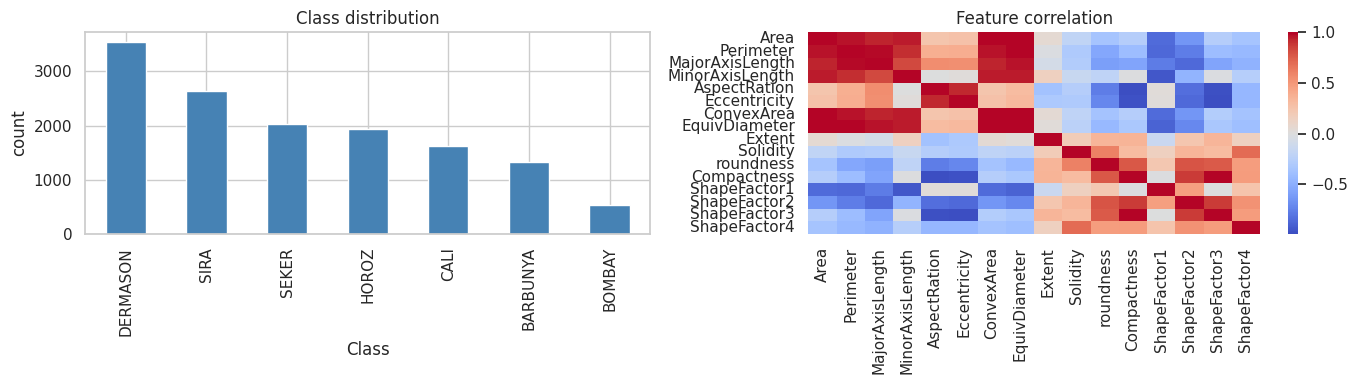

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df[TARGET_COL].value_counts().plot(kind="bar", ax=ax[0], color="steelblue")
ax[0].set_title("Class distribution"); ax[0].set_ylabel("count")
sns.heatmap(df.drop(columns=[TARGET_COL]).corr(), cmap="coolwarm", center=0, ax=ax[1])
ax[1].set_title("Feature correlation")
plt.tight_layout(); plt.show()

## 4. Prepare data
All 16 features are numeric with no missing values, so scaling is the only preprocessing needed.
The scaler sits **inside** each pipeline, so it is fitted on training data only and saved with the model.

In [11]:
X = df.drop(columns=[TARGET_COL])
le = LabelEncoder()
y = le.fit_transform(df[TARGET_COL].astype(str))
classes = le.classes_.tolist()
n_classes = len(classes)
print("Classes:", classes)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Classes: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']
Train: (10888, 16) | Test: (2723, 16)


## 5. Define the five models

In [13]:
models = {
    "Logistic Regression":    LogisticRegression(max_iter=2000),
    "Decision Tree":          DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE),
    "KNN":                    KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes":            GaussianNB(),
    "Support Vector Machine": SVC(probability=True, random_state=RANDOM_STATE),
}

## 6. Train, evaluate, save
Each model is trained in a scaling pipeline, evaluated on the test split and saved with joblib.
SVM with `probability=True` is slower than the others on ~10.9k training rows.

In [15]:
results, fitted, preds = {}, {}, {}

for name, clf in models.items():
    pipe = Pipeline([("scale", StandardScaler()), ("clf", clf)])
    pipe.fit(X_train, y_train)
    y_pred  = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)

    results[name] = compute_metrics(y_test, y_pred, y_proba, n_classes)
    fitted[name], preds[name] = pipe, y_pred
    joblib.dump(pipe, os.path.join(MODEL_DIR, name.lower().replace(" ", "_") + ".joblib"))
    print(f"done: {name}")

metrics_table = pd.DataFrame(results).T.round(4)
metrics_table.index.name = "ML Model Name"
metrics_table

done: Logistic Regression
done: Decision Tree
done: KNN
done: Naive Bayes
done: Support Vector Machine


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9214,0.9934,0.9222,0.9214,0.9216,0.9050
Decision Tree,0.9041,0.9789,0.9038,0.9041,0.9038,0.8841
KNN,0.9137,0.9837,0.9144,0.9137,0.9139,0.8956
Naive Bayes,0.8979,0.9902,0.9007,0.8979,0.8981,0.8773
Support Vector Machine,0.9221,0.9937,0.9224,0.9221,0.9222,0.9059


## 7. Save test data, metadata and metrics

In [17]:
test_df = X_test.copy()
test_df[TARGET_COL] = le.inverse_transform(y_test)
test_df.to_csv("test_data.csv", index=False)

meta = {
    "target_col": TARGET_COL,
    "classes": classes,
    "feature_cols": X.columns.tolist(),
    "models": {n: n.lower().replace(" ", "_") + ".joblib" for n in fitted},
}
with open(os.path.join(MODEL_DIR, "meta.json"), "w") as f:
    json.dump(meta, f, indent=2)

metrics_table.to_csv(os.path.join(MODEL_DIR, "metrics_table.csv"))
print("Saved test_data.csv:", test_df.shape)
print(os.listdir(MODEL_DIR))

Saved test_data.csv: (2723, 17)
['decision_tree.joblib', 'knn.joblib', 'logistic_regression.joblib', 'meta.json', 'metrics_table.csv', 'naive_bayes.joblib', 'support_vector_machine.joblib']


## 8. README table
Metrics comparison printed as a markdown table.

In [19]:
print(metrics_table.reset_index().to_markdown(index=False))

| ML Model Name          |   Accuracy |    AUC |   Precision |   Recall |     F1 |    MCC |
|:-----------------------|-----------:|-------:|------------:|---------:|-------:|-------:|
| Logistic Regression    |     0.9214 | 0.9934 |      0.9222 |   0.9214 | 0.9216 | 0.905  |
| Decision Tree          |     0.9041 | 0.9789 |      0.9038 |   0.9041 | 0.9038 | 0.8841 |
| KNN                    |     0.9137 | 0.9837 |      0.9144 |   0.9137 | 0.9139 | 0.8956 |
| Naive Bayes            |     0.8979 | 0.9902 |      0.9007 |   0.8979 | 0.8981 | 0.8773 |
| Support Vector Machine |     0.9221 | 0.9937 |      0.9224 |   0.9221 | 0.9222 | 0.9059 |


## 9. Model observations
Confusion matrices and per-class scores show which bean classes each model confuses.

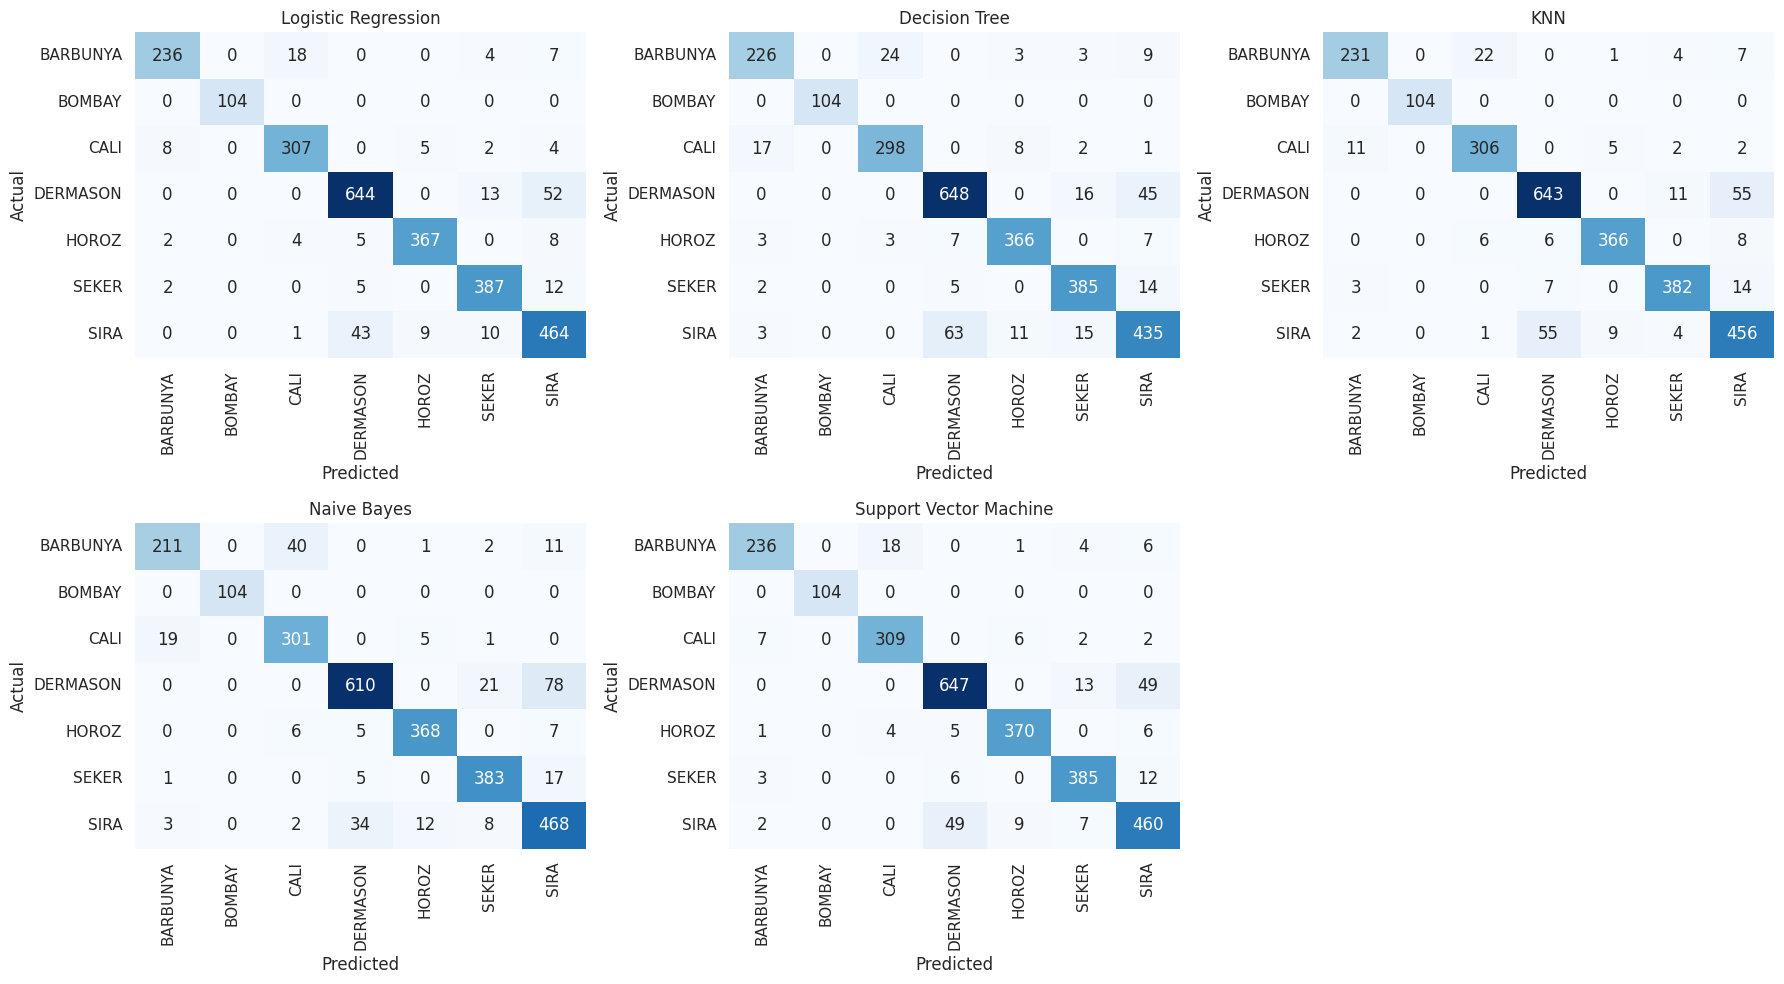

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, (name, y_pred) in zip(axes.ravel(), preds.items()):
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
                xticklabels=classes, yticklabels=classes, ax=ax, cbar=False)
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

In [22]:
for name, y_pred in preds.items():
    print("="*60, "\n", name)
    print(classification_report(y_test, y_pred, target_names=classes, digits=3))

 Logistic Regression
              precision    recall  f1-score   support

    BARBUNYA      0.952     0.891     0.920       265
      BOMBAY      1.000     1.000     1.000       104
        CALI      0.930     0.942     0.936       326
    DERMASON      0.924     0.908     0.916       709
       HOROZ      0.963     0.951     0.957       386
       SEKER      0.930     0.953     0.942       406
        SIRA      0.848     0.880     0.864       527

    accuracy                          0.921      2723
   macro avg      0.935     0.932     0.934      2723
weighted avg      0.922     0.921     0.922      2723

 Decision Tree
              precision    recall  f1-score   support

    BARBUNYA      0.900     0.853     0.876       265
      BOMBAY      1.000     1.000     1.000       104
        CALI      0.917     0.914     0.916       326
    DERMASON      0.896     0.914     0.905       709
       HOROZ      0.943     0.948     0.946       386
       SEKER      0.914     0.948     0.93

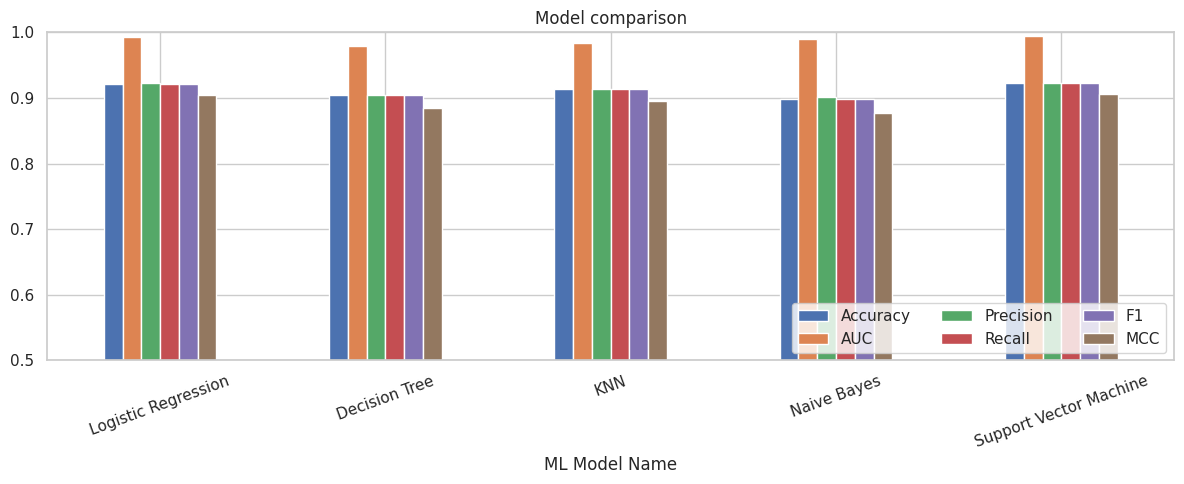

In [23]:
metrics_table.plot(kind="bar", figsize=(12, 5), ylim=(0.5, 1.0))
plt.title("Model comparison"); plt.xticks(rotation=20); plt.legend(loc="lower right", ncol=3)
plt.tight_layout(); plt.show()